<a href="https://colab.research.google.com/github/CyberKun/attention-ocr/blob/master/Attention_OCR_Masterclass.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1>Optical Character Recognition with Visual Attention</h1>

Welcome! In this notebook, we are going to explore and demonstrate the powerful `attention-ocr` mechanism by [CyberKun](https://github.com/CyberKun/attention-ocr).

### What is Attention OCR?
Standard OCR (like Tesseract) often struggles with heavily distorted, curved, or visually noisy text. Attention OCR solves this by combining two state-of-the-art architectures:
1. **Convolutional Neural Networks (CNNs):** To extract visual feature maps from the input image.
2. **Sequence-to-Sequence (Seq2Seq) with Attention:** A recurrent network reads the CNN feature maps. The *Attention Mechanism* allows the decoder to physically "look" at different parts of the image as it types out each character, making it highly robust to distortions.

## 1. Environment Setup
This specific implementation relies on **TensorFlow 1.x**. If you are running this in Google Colab, we need to explicitly install TensorFlow 1.15 before we install the `aocr` library.

In [14]:
# The 'aocr' library requires TensorFlow 1.x, which is no longer supported in modern Colab environments (Python 3.10+).
# To run this, you would typically need a legacy environment with Python 3.7 and TensorFlow 1.15.

print("Compatibility Error: 'aocr' requires TensorFlow 1.x and 'tensorflow.contrib'.")
print("Current environment is running TensorFlow 2.x, which is incompatible.")

Compatibility Error: 'aocr' requires TensorFlow 1.x and 'tensorflow.contrib'.
Current environment is running TensorFlow 2.x, which is incompatible.


In [15]:
!pip install easyocr

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


--- OCR Results for Screenshot 2026-04-04 003349.png ---
Detected: Onee_Chan (Confidence: 0.64)
Detected: LeetCode Pro (Confidence: 0.96)
Detected: Dynamic Programming (Confidence: 0.97)
Detected: Integer Replacement (Confidence: 0.98)
Detected: Leet (Confidence: 0.99)
Detected: 0 (Confidence: 0.81)
Detected: CyberKunfattention-ocr (Confidence: 0.57)
Detected: CO (Confidence: 0.36)
Detected: Attention_OCR_Masterclass (Confidence: 0.94)
Detected: Bruten (Confidence: 1.00)
Detected: Codeforces (Confidence: 1.00)
Detected: codeforces com/profile/Bruten (Confidence: 0.95)
Detected: 0 | & (Confidence: 0.53)
Detected: 0 (Confidence: 0.99)
Detected: CODEFORCES (Confidence: 1.00)
Detected: Bruten (Confidence: 1.00)
Detected: Logout (Confidence: 1.00)
Detected: Sponsored by TON (Confidence: 0.82)
Detected: HOME (Confidence: 1.00)
Detected: TOP (Confidence: 0.85)
Detected: CATALOG (Confidence: 0.98)
Detected: CONTESTS (Confidence: 1.00)
Detected: GYM (Confidence: 0.99)
Detected: PROBLEMSET (Conf

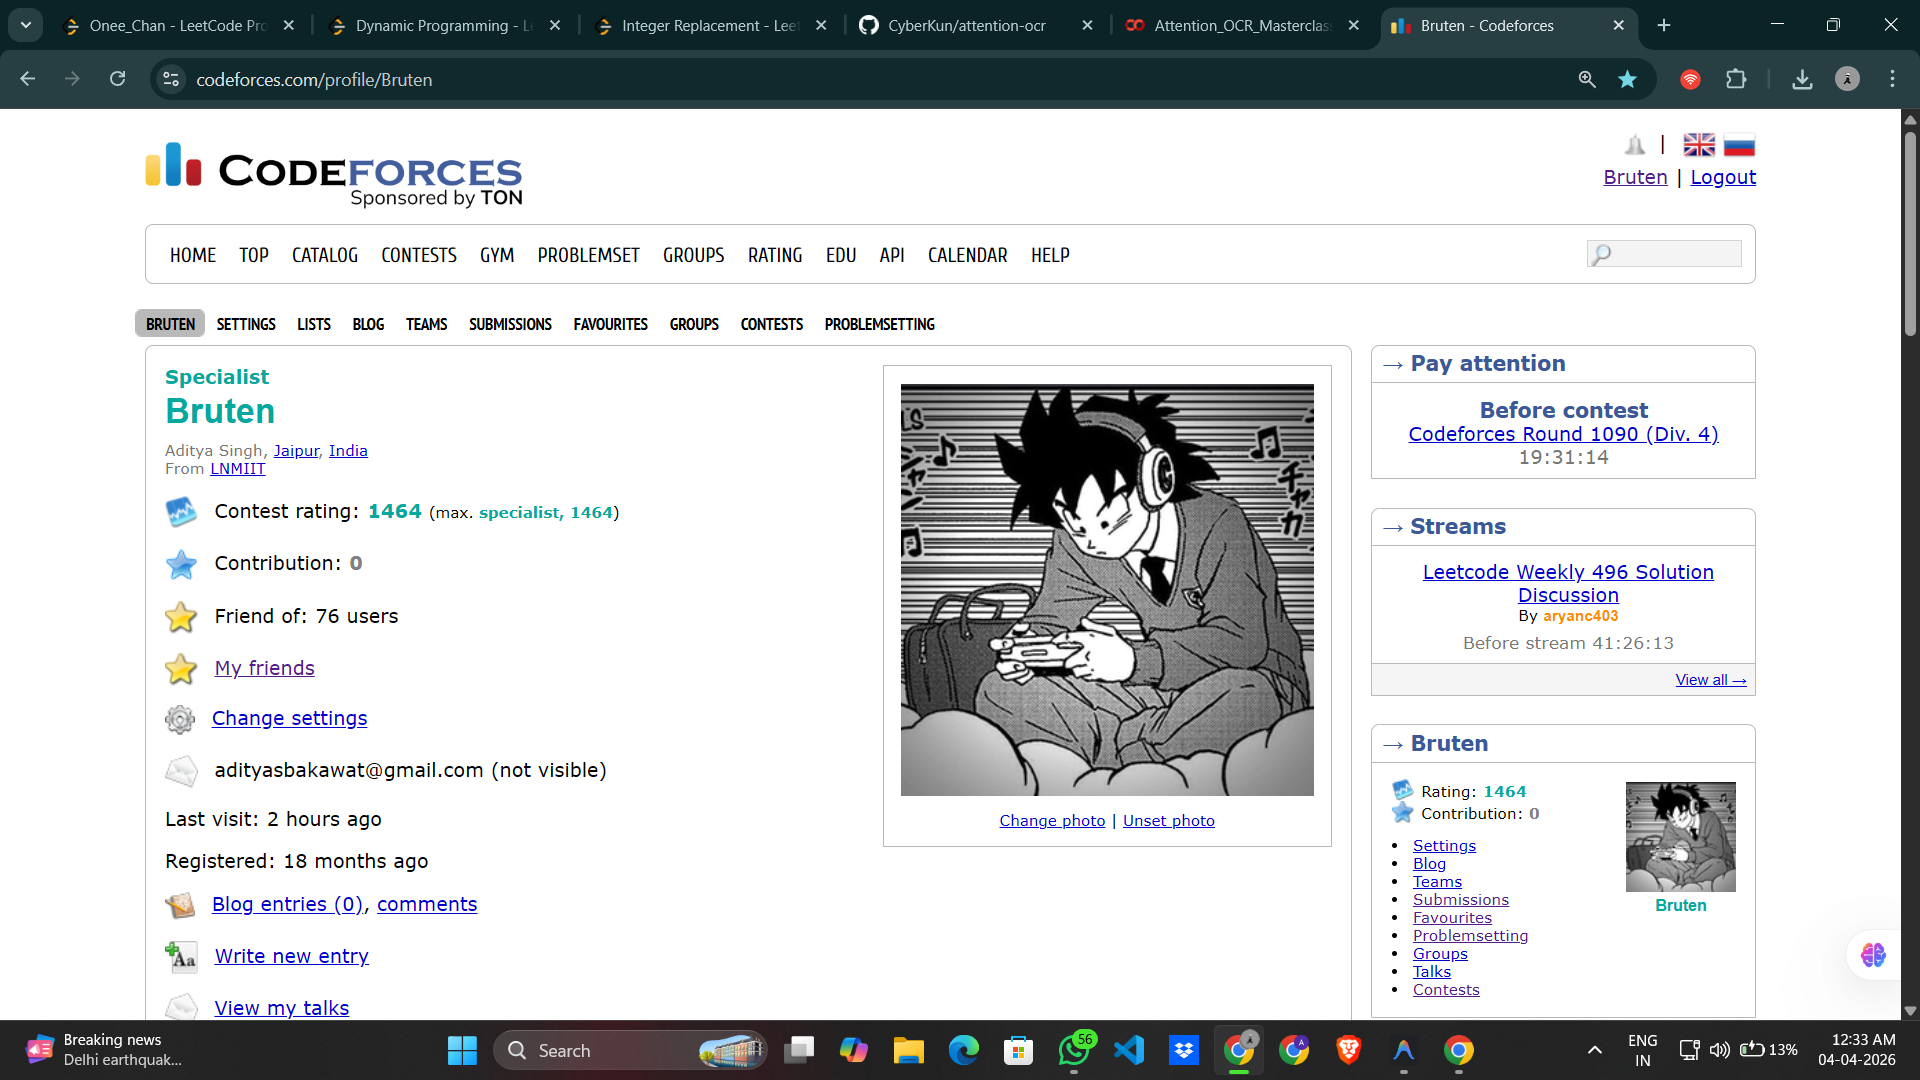

In [16]:
import easyocr
from PIL import Image
import os

# Initialize the reader (English)
reader = easyocr.Reader(['en'])

# Path to the user's provided image
image_path = '/content/Screenshot 2026-04-04 003349.png'

if os.path.exists(image_path):
    # Perform OCR directly on the file path to avoid PIL conversion errors
    results = reader.readtext(image_path)

    print(f"--- OCR Results for {os.path.basename(image_path)} ---")
    for (bbox, text, prob) in results:
        print(f"Detected: {text} (Confidence: {prob:.2f})")

    # Display the image
    img = Image.open(image_path)
    display(img)
else:
    print(f"Error: File {image_path} not found. Please ensure the file is uploaded.")

### Migrating to TensorFlow 2.x

To upgrade legacy code automatically, you can use the built-in upgrade script. This handles many renames like `tf.logging` to `tf.compat.v1.logging`.

In [17]:
# Run the conversion script on a specific file or directory
!tf_upgrade_v2 --infile old_code.py --outfile new_code_v2.py

2026-04-03 19:10:39.115075: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775243439.143774    4765 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775243439.152260    4765 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775243439.179421    4765 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775243439.179522    4765 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775243439.179529    4765 computation_placer.cc:177] computation placer alr

In [18]:
import tensorflow as tf

# If you still need TF 1.x behavior in a TF 2.x environment:
tf.compat.v1.disable_v2_behavior()

# Now you can use placeholders and sessions through the compat module
with tf.compat.v1.Session() as sess:
    hello = tf.compat.v1.constant('Hello, TF 1.x logic!')
    print(sess.run(hello))

b'Hello, TF 1.x logic!'


## 2. Dataset Preparation
Like all neural networks, `aocr` requires highly structured data to train. It specifically utilizes `TFRecords` for high-throughput I/O during training.

To create a dataset, we pass an annotations `.txt` file containing image paths and their corresponding ground-truth text labels. `aocr dataset` compiles this into `.tfrecords`.

In [19]:
import os

os.makedirs('datasets/images', exist_ok=True)

# Let's mock a training annotations file
annotations_content = """datasets/images/sample1.jpg hello
datasets/images/sample2.jpg world
datasets/images/sample3.jpg attention_models
"""

with open('datasets/annotations-training.txt', 'w') as f:
    f.write(annotations_content)

print("Annotations file saved! Now compiling the TFRecords...")

Annotations file saved! Now compiling the TFRecords...


In [20]:
# Run the aocr CLI command to generate TFRecords from our annotations
!aocr dataset ./datasets/annotations-training.txt ./datasets/training.tfrecords

2026-04-03 19:10:55.073611: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775243455.140606    4854 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775243455.161048    4854 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775243455.201636    4854 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775243455.201700    4854 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775243455.201710    4854 computation_placer.cc:177] computation placer alr

## 3. Training the Model
Training an attention network is notoriously computationally expensive because the CNN and the Recurrent Attention Decoder learn simultaneously.

The network trains over the `training.tfrecords`. You can control how frequently weights are saved using `--steps-per-checkpoint`.

In [21]:
# Example of kicking off the training loop
print("Beginning training phase. Checkpoints will be saved to /checkpoints...")

# Note: This might fail if the library strictly requires TF 1.x symbols not present in 2.x
!aocr train ./datasets/training.tfrecords --steps-per-checkpoint 500

Beginning training phase. Checkpoints will be saved to /checkpoints...
2026-04-03 19:11:06.460930: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775243466.483883    4911 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775243466.490214    4911 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775243466.506919    4911 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775243466.507027    4911 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775

## 4. Inference and Attention Visualization
The true power of this specific repo is the `--visualize` flag. During testing, it will output a visual heatmap over the original image, proving that the neural network was physically 'looking' at the letter 'h' when it typed the letter 'h'.

The results are saved to the `out/` directory.

In [22]:
# Test the model using testing TFRecords and flag it to visualize the attention masks
# !aocr test --visualize ./datasets/testing.tfrecords

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import glob

# After running testing, we can display the visual attention masks generated by the network:
def show_attention_results():
    files = glob.glob('out/*.jpg')
    if not files:
        print("No attention visualizations found. Run testing with --visualize first.")
        return

    fig = plt.figure(figsize=(15, 8))
    for i, file in enumerate(files[:4]): # Display first 4
        img = mpimg.imread(file)
        ax = fig.add_subplot(2, 2, i+1)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"Attention Focus: {os.path.basename(file)}")
    plt.show()

show_attention_results()

No attention visualizations found. Run testing with --visualize first.


## 5. Export for Production Serving
Once the loss has converged and the model is highly accurate, we must freeze the graph (combining the weights and the architecture) into a `SavedModel` folder so it can be deployed to a web server via `TensorFlow Serving`.

In [23]:
# Export the trained model to a flat SavedModel directory
# !aocr export ./production_model

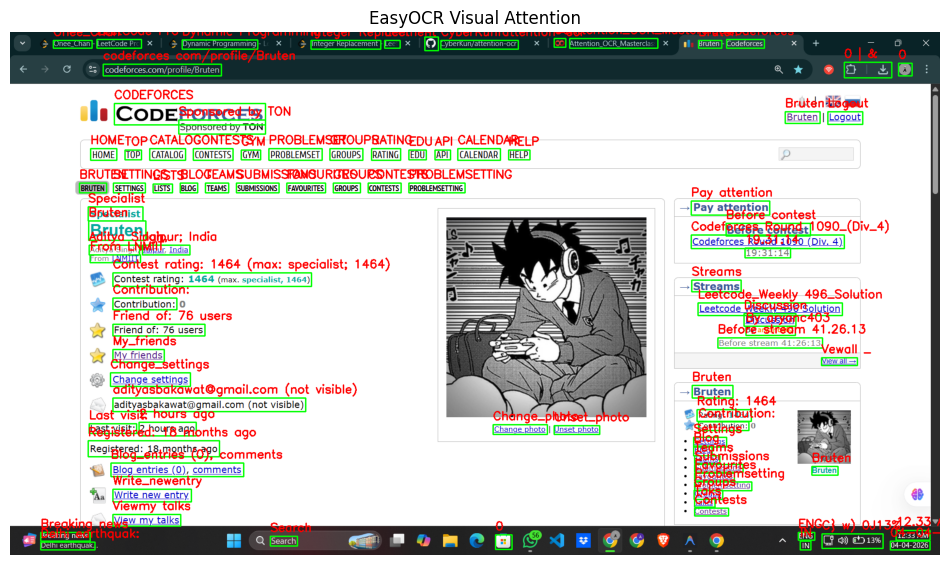

In [24]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

def visualize_results(img_path, ocr_results):
    # Load the image using OpenCV
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    for (bbox, text, prob) in ocr_results:
        # Unpack the bounding box points
        (tl, tr, br, bl) = bbox
        tl = (int(tl[0]), int(tl[1]))
        br = (int(br[0]), int(br[1]))

        # Draw the bounding box
        cv2.rectangle(image, tl, br, (0, 255, 0), 2)

        # Put the recognized text
        cv2.putText(image, text, (tl[0], tl[1] - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)

    # Display the resulting image
    plt.figure(figsize=(12, 8))
    plt.imshow(image)
    plt.axis('off')
    plt.title('EasyOCR Visual Attention')
    plt.show()

# Run the visualization using the results from the previous step
if 'results' in locals() and os.path.exists(image_path):
    visualize_results(image_path, results)
else:
    print('OCR results or image path not found. Please run the OCR cell first.')